In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_csv('../results/hyperparam_sweep_20250829_160001.csv')
df2 = pd.read_csv('../results/hyperparam_sweep_20250830_031143.csv')
df3 = pd.read_csv('../results/hyperparam_sweep_20250830_114144.csv')
df4 = pd.read_csv('../results/hyperparam_sweep_20250830_192536.csv')
df5 = pd.read_csv('../results/hyperparam_sweep_20250831_014156.csv')
df6 = pd.read_csv('../results/hyperparam_sweep_20250831_142233.csv')
df7 = pd.read_csv('../results/hyperparam_sweep_20250902_143523.csv')

df = pd.concat([df1, df2, df3, df4, df5, df6, df7])
df.drop_duplicates(inplace=True)
# df.head(20)

In [28]:
print(df['HIDDEN_SIZE'].unique())
print((df['HIDDEN_SIZE'] == 256).sum())

[ 128  256  512 1024]
35


In [29]:
dfg = df[(df['max_r2_throughput'] >= 0.5) & (df['max_r2_delay'] >= 0.4)]
df.shape

(210, 12)

In [30]:
x = 'FILTER_LEN'
win_l = df[x].unique()

for l in win_l:
    fl = (df[x] == l).sum()
    flg = (dfg[x] == l).sum()
    print(f"For FILTER_LEN {l}: {flg / fl * 100} % | Samples counted: {fl}")

For FILTER_LEN 5: 1.0752688172043012 % | Samples counted: 93
For FILTER_LEN 10: 5.982905982905983 % | Samples counted: 117


In [31]:
win_l = df['WINDOW_LEN'].unique()

for l in win_l:
    fl = (df['WINDOW_LEN'] == l).sum()
    flg = (dfg['WINDOW_LEN'] == l).sum()
    print(f"For window len {l}: {flg / fl * 100} % | Samples counted: {fl}")

For window len 10: 1.5625 % | Samples counted: 64
For window len 15: 6.8181818181818175 % | Samples counted: 88
For window len 25: 1.7241379310344827 % | Samples counted: 58


In [32]:
fut_l = df['FUTURE_WIN_LEN'].unique()

for l in fut_l:
    fl = (df['FUTURE_WIN_LEN'] == l).sum()
    flg = (dfg['FUTURE_WIN_LEN'] == l).sum()
    print(f"For future win len {l}: {flg / fl * 100} % | Samples counted: {fl}")


For future win len 3: 0.0 % | Samples counted: 69
For future win len 5: 9.195402298850574 % | Samples counted: 87
For future win len 10: 0.0 % | Samples counted: 54


In [33]:
nl = df['NUM_LAYERS'].unique()

for l in nl:
    fl = (df['NUM_LAYERS'] == l).sum()
    flg = (dfg['NUM_LAYERS'] == l).sum()

    print(f"num layer: {l}: {flg / fl * 100} | Samples counted: {fl}")

num layer: 2: 2.4390243902439024 | Samples counted: 82
num layer: 3: 9.375 | Samples counted: 64
num layer: 4: 0.0 | Samples counted: 36
num layer: 8: 0.0 | Samples counted: 28


num_layers = 2 / 3

In [34]:
hs = df['HIDDEN_SIZE'].unique()

for s in hs:
    fl = (df['HIDDEN_SIZE'] == s).sum()
    flg = (dfg['HIDDEN_SIZE'] == s).sum()
    print(f"HS: {s}: {flg / fl * 100}% | Samples counted: {fl}")

HS: 128: 1.2195121951219512% | Samples counted: 164
HS: 256: 5.714285714285714% | Samples counted: 35
HS: 512: 30.0% | Samples counted: 10
HS: 1024: 100.0% | Samples counted: 1


In [35]:
lrs = df['LEARNING_RATE'].unique()

for lr in lrs:
    l = (df['LEARNING_RATE'] == lr).sum()
    lg = (dfg['LEARNING_RATE'] == lr).sum()
    print(f"LR: {lr}: {lg * 100 / l} % | Samples counted: {l}")

LR: 0.001: 4.477611940298507 % | Samples counted: 134
LR: 0.01: 2.7777777777777777 % | Samples counted: 72
LR: 0.1: 0.0 % | Samples counted: 4


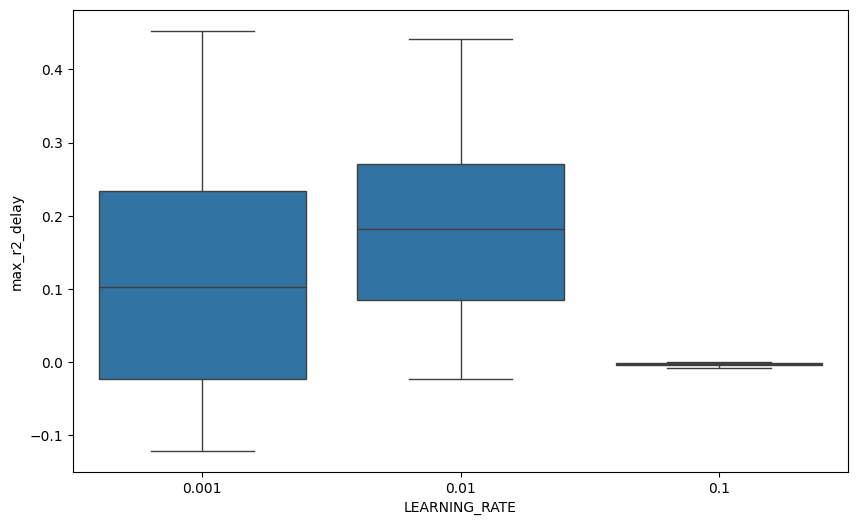

In [38]:
import seaborn as sns

plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='LEARNING_RATE', y='max_r2_delay')
plt.show()

In [51]:
import seaborn as sns

for cols in df:
    if cols == 'max_r2_throughput':
        break

    print(cols, ": ", df['max_r2_delay'].corr(df[cols]))

BATCH_SIZE :  -0.07335855157026196
LEARNING_RATE :  -0.0723929683041474
NUM_EPOCHS :  nan
HIDDEN_SIZE :  0.21357080896143235
NUM_LAYERS :  -0.2535339014469932
FUTURE_WIN_LEN :  -0.370515544821494
WINDOW_LEN :  0.0770937836113628
FILTER_LEN :  0.13899907790219782


/home/ushtro/Documents/AIML/fed_l/myenv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/ushtro/Documents/AIML/fed_l/myenv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
